In [1]:

from scipy.spatial import cKDTree
from trackpy.utils import guess_pos_columns
import numpy as np
import pandas as pd
from pandas import DataFrame
import trackpy
import math
import csv
from trackpy.utils import pandas_concat
import pandas
import matplotlib.pyplot as plt

In [2]:
# Maximum number of elements in the array of all distances.
# Should be roughly (bytes of available memory)/16
MAX_ARRAY_SIZE = 1e8

In [3]:
df = pd.read_csv(r'/Users/rayyan/Desktop/honors_indep_study/Data/linked result.csv')
# # Getting rid of unneeded columns 
df = df.filter(items = ['particle_id','x', 'y','Area','frame'])

# # Putting in trackpy format
df.columns= ['particle_id','x', 'y','Area','frame']


Particles in df, frame 51 : 2738
Frame range in df: 1 to 401


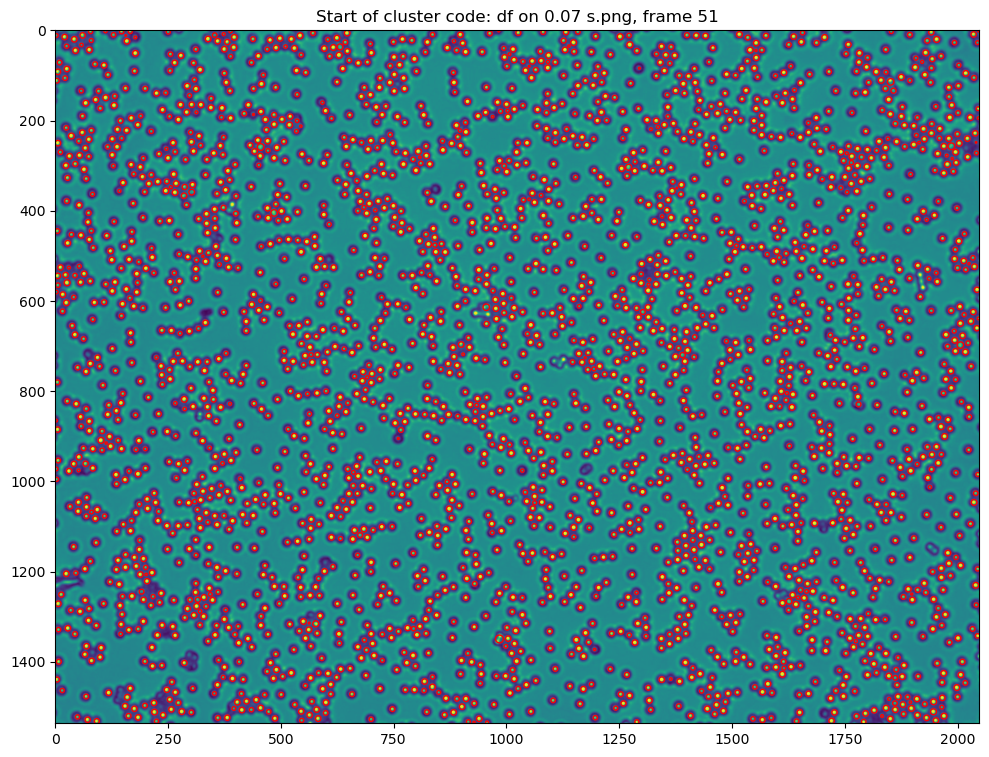

In [4]:
from matplotlib.patches import Circle
from matplotlib.collections import PatchCollection

frame_num = 51
d51 = df[df['frame'] == frame_num]
print("Particles in df, frame", frame_num, ":", len(d51))
print("Frame range in df:", df['frame'].min(), "to", df['frame'].max())

img = plt.imread(r'/Users/rayyan/Desktop/honors_indep_study/0.07 s.png')

# full frame: (0, 2048), (1536, 0)   zoomed on the cluster: (1600, 1690), (1010, 900)
XLIM, YLIM = (0, 2048), (1536, 0)

fig, ax = plt.subplots(figsize=(12, 9))
ax.imshow(img)

rings = [Circle((x, y), np.sqrt(a / np.pi))
         for x, y, a in zip(d51['x'], d51['y'], d51['Area'])]
ax.add_collection(PatchCollection(rings, facecolor='none', edgecolor='red', linewidth=1))

ax.set_xlim(*XLIM)
ax.set_ylim(*YLIM)
ax.set_title(f'Start of cluster code: df on 0.07 s.png, frame {frame_num}')
plt.show()

In [5]:
#df['Particle'] = pd.Series([x for x in range(len(df.index))])
#df["particle"] = df["particle"] + 1
display(df.head())

,particle_id,x,y,Area,frame
0,0,8.605,3.263,76,1
1,0,7.114,3.057,70,2
2,0,6.536,2.464,55,3
3,0,4.585,3.093,59,4
4,0,3.760,4.623,73,5


In [6]:
# from Clustering.ipynb, before the cluster_size filter was applied
print("Unfiltered particles in frame 1 (post-linking):", len(df[df['frame'] == 1]))

Unfiltered particles in frame 1 (post-linking): 2766


In [7]:
def cluster(f, separation, pos_columns=None, t_column='frame'):
    """ Cluster features from one or several frames.
    A cluster is defined as the largest group of features of which each feature
    has at least one feature closer than ``separation``.
    Parameters
    ----------
    f: DataFrame
        pandas DataFrame containing pos_columns and t_column
    separation: number or tuple
        Separation distance below which particles are considered inside cluster
    pos_columns: list of strings, optional
        Column names that contain the position coordinates.
        Defaults to ['y', 'x'] (or ['z', 'y', 'x'] if 'z' exists)
    t_column: string
        Column name containing the frame number (Default: 'frame')
    Returns
    -------
    Copy of ``f`` with added "cluster" and "cluster_size" column
    """
    if t_column not in f:
        f[t_column] = 0
        remove_t_column = True
    else:
        remove_t_column = False

    result = pandas_concat(x[1] for x in cluster_iter(f, separation, pos_columns,
                                                   t_column))

    if remove_t_column:
        del f[t_column]
    
    
    return result

In [8]:
clus=trackpy.static.cluster(df, 24, pos_columns=None, t_column='frame') # threshold goes in these params







clus = clus[clus['cluster_size'].between(3, 7)]


# now i will add a new column called "particle_type" which will tell us whether the particle is an active one or a passive one
# the area cutoff which determines whether the particle is active or passive is calculated in the linking code using kde


clus['particle_type'] = np.where(clus['Area'] >= 103, 'passive', 'active')



clus.to_csv(r'/Users/rayyan/Desktop/honors_indep_study/Results/Clustering_Results.csv', index=False)
print(clus)


#df.to_csv(r'D:\Pronay\trial for area detection\file_result.csv')

         particle_id         x         y  Area  frame  cluster  cluster_size  \
22                 2   426.450  1012.742   120      1        2             6   
824                4   447.027  1013.581    74      1        2             6   
1225               5  1036.585  1014.553    94      1        5             5   
1404               6  1663.939  1013.535    57      1        6             4   
2612              10   405.876  1017.489    93      1        2             6   
...              ...       ...       ...   ...    ...      ...           ...   
1102364        20351     2.183    53.256    41    401  1098509             6   
1102367        20354   601.362     1.776    29    401  1099756             6   
1102369        20356   377.500   125.500    13    401  1098725             3   
1102376        20363   235.750   456.167    12    401  1098459             4   
1102381        20368  2045.147  1534.559    17    401  1100393             4   

        particle_type  
22            p

In [9]:
# This code basically puts every particle in a cluster and tells us how many particles are in that cluster,
#the cluster column tells us the id of the cluster and the cluster_size tells us the amount of particles in the cluster.

In [10]:
clus.head()

,particle_id,x,y,Area,frame,cluster,cluster_size,particle_type
22,2,426.450,1012.742,120,1,2,6,passive
824,4,447.027,1013.581,74,1,2,6,active
1225,5,1036.585,1014.553,94,1,5,5,active
1404,6,1663.939,1013.535,57,1,6,4,active
2612,10,405.876,1017.489,93,1,2,6,active


In [11]:
# Count active and passive particles within each (frame, cluster) group
cluster_counts = clus.groupby(['frame', 'cluster'])['particle_type'].value_counts().unstack(fill_value=0)
cluster_counts = cluster_counts.rename(columns={'active': 'N_active', 'passive': 'N_passive'}).reset_index()

# Merge those counts back onto every particle row
clus = clus.merge(cluster_counts[['frame', 'cluster', 'N_active', 'N_passive']], on=['frame', 'cluster'], how='left')

In [12]:
mismatch = clus[clus['N_active'] + clus['N_passive'] != clus['cluster_size']]
print("Mismatched rows:", len(mismatch))

Mismatched rows: 0


In [13]:
clus.head()

,particle_id,x,y,Area,frame,cluster,cluster_size,particle_type,N_active,N_passive
0,2,426.450,1012.742,120,1,2,6,passive,3,3
1,4,447.027,1013.581,74,1,2,6,active,3,3
2,5,1036.585,1014.553,94,1,5,5,active,3,2
3,6,1663.939,1013.535,57,1,6,4,active,2,2
4,10,405.876,1017.489,93,1,2,6,active,3,3


In [14]:
clus.head(100)

,particle_id,x,y,Area,frame,cluster,cluster_size,particle_type,N_active,N_passive
0,2,426.450,1012.742,120,1,2,6,passive,3,3
1,4,447.027,1013.581,74,1,2,6,active,3,3
2,5,1036.585,1014.553,94,1,5,5,active,3,2
3,6,1663.939,1013.535,57,1,6,4,active,2,2
4,10,405.876,1017.489,93,1,2,6,active,3,3
...,...,...,...,...,...,...,...,...,...,...
95,372,1061.661,804.048,124,1,372,7,passive,3,4
96,374,1674.962,803.610,91,1,374,4,active,2,2
97,375,1886.987,804.349,119,1,354,5,passive,3,2
98,376,213.878,832.071,119,1,385,5,passive,3,2


In [15]:
# to get the n_active n_passive we made seperate buckets of particles which depend on the frame and cluster
# so each same cluster and frame is put in one bucket then we count the num of active and passive in those

In [16]:
clus.to_csv(r'/Users/rayyan/Desktop/honors_indep_study/Results/Clustering_Results.csv', index=False)

In [17]:
def plot_classification(frame_num, image_path):
    check = clus[clus['frame'] == frame_num]
    active = check[check['particle_type'] == 'active']
    passive = check[check['particle_type'] == 'passive']

    img = plt.imread(image_path)

    plt.figure(figsize=(12, 10))
    plt.imshow(img)
    plt.scatter(active['x'], active['y'], s=40, facecolors='none',
                edgecolors='red', linewidths=1.5, label=f'active ({len(active)})')
    plt.scatter(passive['x'], passive['y'], s=40, facecolors='none',
                edgecolors='lime', linewidths=1.5, label=f'passive ({len(passive)})')
    plt.title(f'Active vs Passive classification — frame {frame_num}')
    plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0)
    plt.tight_layout()
    plt.show()

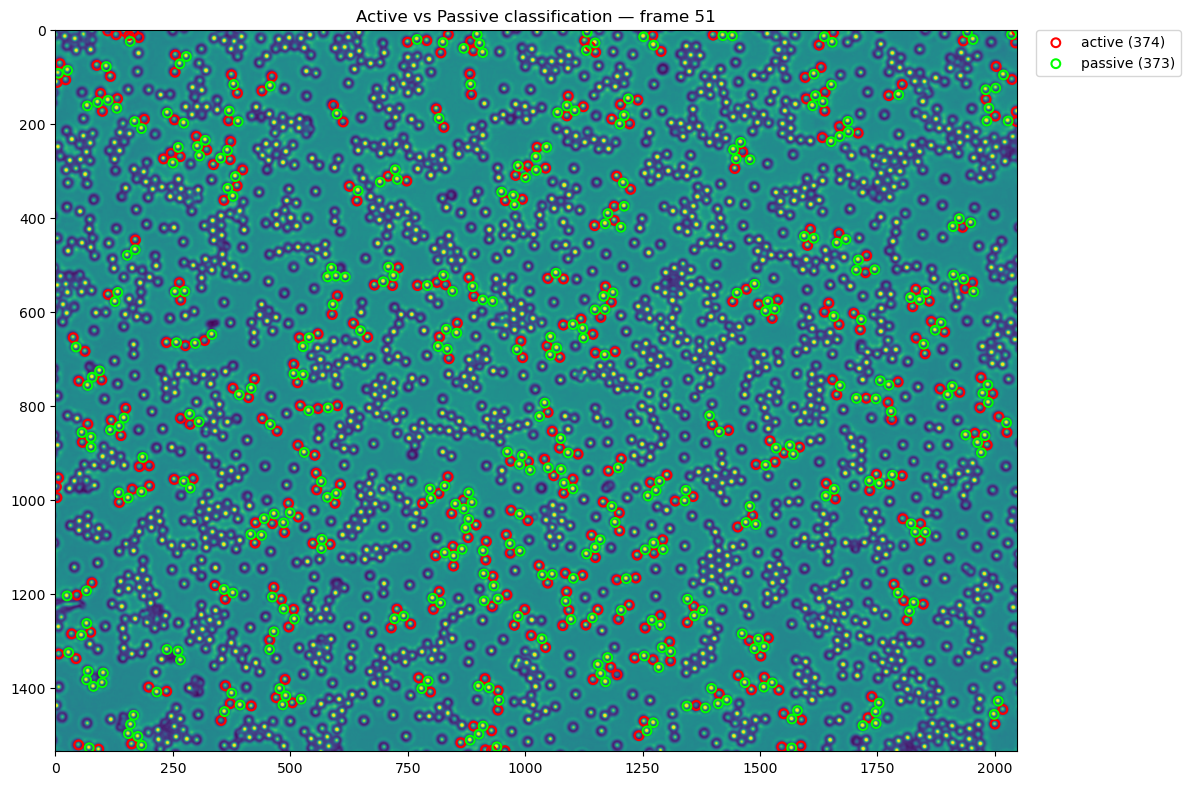

In [18]:
plot_classification(51, r'/Users/rayyan/Desktop/honors_indep_study/0.07 s.png')

In [19]:
print(clus.groupby('cluster')['frame'].nunique().max())

1
